<a href="https://colab.research.google.com/github/ettifourisalma1626encg-create/25007729_ETTIFOURI_SALMA_FIN2/blob/main/projet_F15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import pandas as pd

gdp = pd.read_csv("/content/GDPC1.csv")
sentiment = pd.read_csv("/content/UMCSENT.csv")

display(gdp.head())
display(sentiment.head())


,observation_date,GDPC1
0,1947-01-01,2182.681
1,1947-04-01,2176.892
2,1947-07-01,2172.432
3,1947-10-01,2206.452
4,1948-01-01,2239.682


,observation_date,UMCSENT
0,1952-11-01,86.2
1,1952-12-01,NaN
2,1953-01-01,NaN
3,1953-02-01,90.7
4,1953-03-01,NaN


In [10]:
print("GDP dataset:")
print("Dimensions:", gdp.shape)
print("Columns:", gdp.columns.tolist())
print("Missing values:")
print(gdp.isnull().sum())

print("\nConsumer Sentiment dataset:")
print("Dimensions:", sentiment.shape)
print("Columns:", sentiment.columns.tolist())
print("Missing values:")
print(sentiment.isnull().sum())

GDP dataset:
Dimensions: (319, 2)
Columns: ['observation_date', 'GDPC1']
Missing values:
observation_date    0
GDPC1               0
dtype: int64

Consumer Sentiment dataset:
Dimensions: (887, 2)
Columns: ['observation_date', 'UMCSENT']
Missing values:
observation_date      0
UMCSENT             210
dtype: int64


In [11]:
print("GDP:")
gdp.info()

print("\nConsumer Sentiment:")
sentiment.info()

print("\nFirst rows:")
display(gdp.head())
display(sentiment.head())

GDP:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  319 non-null    object 
 1   GDPC1             319 non-null    float64
dtypes: float64(1), object(1)
memory usage: 5.1+ KB

Consumer Sentiment:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 887 entries, 0 to 886
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  887 non-null    object 
 1   UMCSENT           677 non-null    float64
dtypes: float64(1), object(1)
memory usage: 14.0+ KB

First rows:


,observation_date,GDPC1
0,1947-01-01,2182.681
1,1947-04-01,2176.892
2,1947-07-01,2172.432
3,1947-10-01,2206.452
4,1948-01-01,2239.682


,observation_date,UMCSENT
0,1952-11-01,86.2
1,1952-12-01,NaN
2,1953-01-01,NaN
3,1953-02-01,90.7
4,1953-03-01,NaN


In [12]:
# Identify the date column in each dataset
print("GDP columns:", gdp.columns.tolist())
print("Sentiment columns:", sentiment.columns.tolist())

# Convert the first column to dates
gdp.iloc[:, 0] = pd.to_datetime(gdp.iloc[:, 0])
sentiment.iloc[:, 0] = pd.to_datetime(sentiment.iloc[:, 0])

print("Dates converted successfully!")

GDP columns: ['observation_date', 'GDPC1']
Sentiment columns: ['observation_date', 'UMCSENT']
Dates converted successfully!


In [13]:
# Standardize column names
gdp.columns = ["DATE", "GDP"]
sentiment.columns = ["DATE", "SENTIMENT"]

# Make dates the index
gdp["DATE"] = pd.to_datetime(gdp["DATE"])
sentiment["DATE"] = pd.to_datetime(sentiment["DATE"])

gdp = gdp.set_index("DATE")
sentiment = sentiment.set_index("DATE")

# Convert monthly sentiment into quarterly averages
sentiment_q = sentiment.resample("QS").mean()

# Combine GDP and sentiment
data = gdp.join(sentiment_q, how="inner")

# Calculate quarterly GDP growth (%)
data["GDP_GROWTH"] = data["GDP"].pct_change() * 100

data = data.dropna()

display(data.head())
print("Dataset dimensions:", data.shape)

,GDP,SENTIMENT,GDP_GROWTH
DATE,,,
1953-01-01,2896.811,90.7,1.859040
1953-07-01,2902.785,80.8,-0.562516
1953-10-01,2858.845,80.7,-1.513719
1954-01-01,2845.192,82.0,-0.477570
1954-04-01,2848.305,82.9,0.109413


Dataset dimensions: (286, 3)


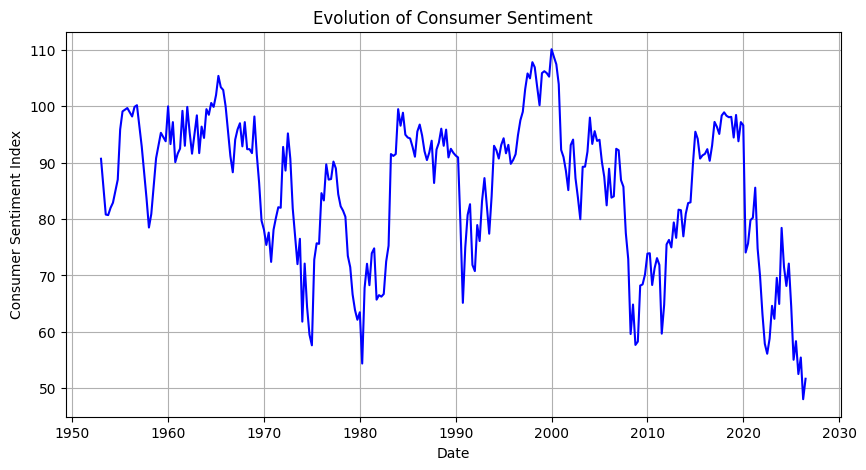

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(data.index, data["SENTIMENT"], color="blue")

plt.title("Evolution of Consumer Sentiment")
plt.xlabel("Date")
plt.ylabel("Consumer Sentiment Index")
plt.grid(True)
plt.show()

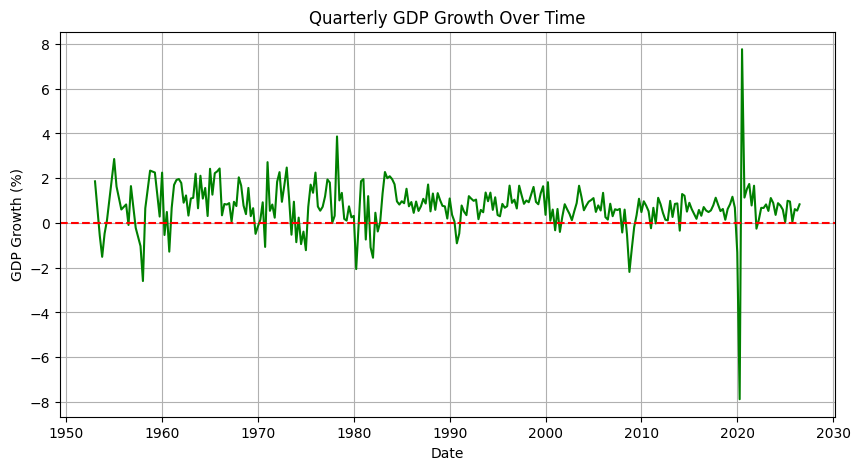

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(data.index, data["GDP_GROWTH"], color="green")

plt.title("Quarterly GDP Growth Over Time")
plt.xlabel("Date")
plt.ylabel("GDP Growth (%)")

plt.axhline(0, color="red", linestyle="--")
plt.grid(True)
plt.show()


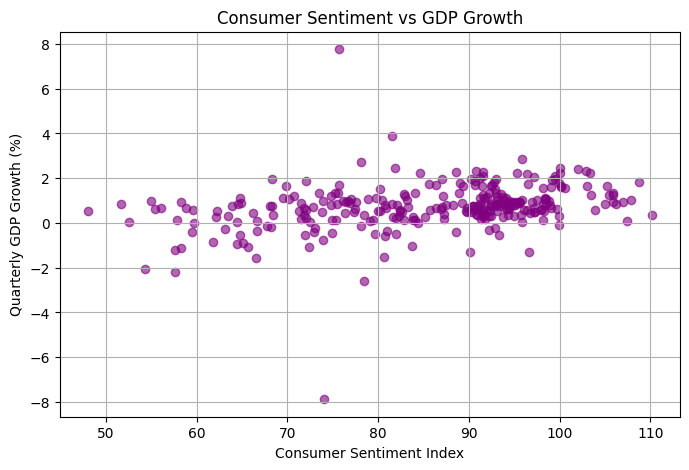

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(data["SENTIMENT"], data["GDP_GROWTH"],
            color="purple", alpha=0.6)

plt.title("Consumer Sentiment vs GDP Growth")
plt.xlabel("Consumer Sentiment Index")
plt.ylabel("Quarterly GDP Growth (%)")

plt.grid(True)
plt.show()

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# Sort data chronologically
data = data.sort_index().copy()

# Use sentiment from the previous quarter
# to predict growth in the current quarter
data["SENTIMENT_LAG1"] = data["SENTIMENT"].shift(1)
model_data = data.dropna(subset=["SENTIMENT_LAG1", "GDP_GROWTH"])

X = model_data[["SENTIMENT_LAG1"]]
y = model_data["GDP_GROWTH"]

# Chronological split: 80% training, 20% testing
split = int(len(model_data) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 228
Testing observations: 57


In [19]:
model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model trained successfully!")
print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Model trained successfully!
Coefficient: 0.024970256755242545
Intercept: -1.4097643314395092


In [20]:
# Naive baseline: mean GDP growth in training data
baseline_pred = np.full(len(y_test), y_train.mean())

results = pd.DataFrame({
    "Model": ["Naive baseline", "Linear Regression"],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        np.sqrt(mean_squared_error(y_test, y_pred))
    ],
    "MAE": [
        mean_absolute_error(y_test, baseline_pred),
        mean_absolute_error(y_test, y_pred)
    ]
})

display(results)

,Model,RMSE,MAE
0,Naive baseline,1.555638,0.623306
1,Linear Regression,1.647789,0.772572


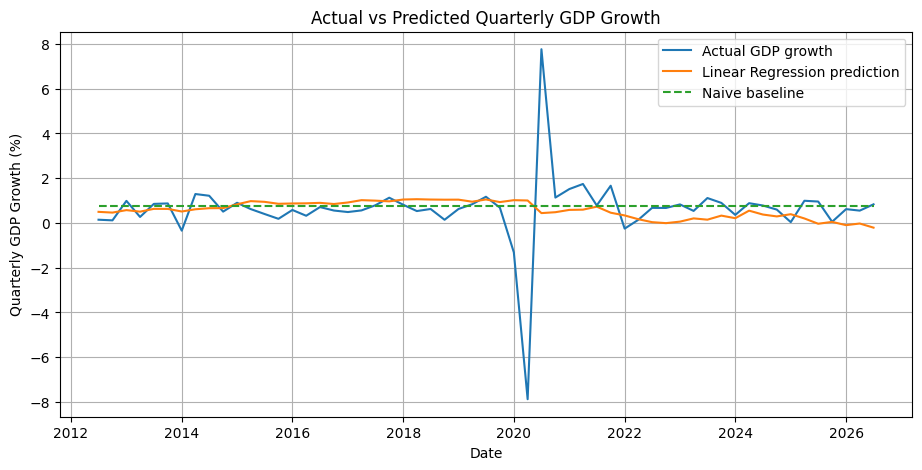

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

plt.plot(y_test.index, y_test, label="Actual GDP growth")
plt.plot(y_test.index, y_pred, label="Linear Regression prediction")
plt.plot(y_test.index, baseline_pred, "--", label="Naive baseline")

plt.title("Actual vs Predicted Quarterly GDP Growth")
plt.xlabel("Date")
plt.ylabel("Quarterly GDP Growth (%)")
plt.legend()
plt.grid(True)
plt.show()